# 03 · Five footprints, and a building the model has never seen

**Milestone 3.** The surrogate now takes the footprint (L_x, L_y) as an input, next to the
soil. Two questions:

1. Trained on all five footprints, how well does it predict **new soils**?
2. Trained on four footprints, how well does it predict the **fifth**, a building it has never
   seen (*leave-one-footprint-out*)?

Two ways of representing the curves are compared: the Milestone 2 approach (scale each term,
PCA, GP), and a **two-part** model that predicts each term's static stiffness and, separately,
the curve's shape relative to it, the split engineers use in K = K_static · (k + i·a₀·c).

The band is **0.45–15 Hz** from here on (see `ml/README.md`).

## In plain words

- **New soils on known footprints:** trained on 256 soils × 5 footprints, the two-part model
  predicts the 160 hold-out cases with a typical error of about **3 %**, and the worst term
  within about **11 %** for 95 % of soils. (One footprint with 1,024 soils, section 1: 1.5 %
  and 5.4 %.)
- **A new building between known sizes** (m45x15 or m60x15 left out): about **5 %** typical,
  **11 %** worst term. The model has learned how the footprint changes the impedance.
- **A new building outside the range** (the shortest, the longest, or the only square one):
  the plain model fails, because a GP drifts back to the average away from its data. Two fixes
  that come from physics rather than more simulations (a power-law trend, and rotated twins of
  each footprint) **halve the average error** in those cases.
- **What it means:** the surrogate interpolates in geometry; to predict genuinely different
  buildings it needs more variety of footprints, which is exactly what new meshes (squarer,
  wider) would give it.
- The fixed recipe (two-part + trend + rotated twins) goes to notebook 04, which uses the GPU to
  train on all the soils.

Run time on a fast desktop CPU: about 45 minutes (about 25 GP fits).

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from surrogate import style
from surrogate.data import concat, load_dataset, make_targets, rotate_90, targets_to_K
from surrogate.experiments import log_experiment, read_experiments
from surrogate.metrics import summarize, target_errors
from surrogate.models import PCAGP, StaticShapeGP, input_features

style.apply()
ds = load_dataset()                       # 0.45-14.95 Hz, ref33x31 at its centroid
f = ds.freqs
MESHES = style.MESH_ORDER
QUICK = False        # True: tiny sizes, only to check that the notebook runs end to end
N_SOILS = 16 if QUICK else 256   # training soils per footprint (sections 2-3); 512 would be ~8x slower per fit (cost ~ n^3)
N_FIX = 16 if QUICK else 128     # soils per footprint for section 4 (the rotated twins double the cases)
N_COMPONENTS = 20
LOG = (lambda *args, **kw: None) if QUICK else log_experiment     # QUICK runs leave the experiment table alone

train_all = ds.select(split="train").head_per_mesh(N_SOILS)      # the same N soils on every footprint
test_all = ds.select(split="test")                                # 32 hold-out soils per footprint
print(f"{len(f)} frequencies, {f[0]:g}-{f[-1]:g} Hz | training cases {len(train_all)} | test cases {len(test_all)}")
print(*ds.notes, sep="\n")

59 frequencies, 0.45-14.95 Hz | training cases 1280 | test cases 160
loaded dataset_v1.npz
ref33x31: K moved from NRADIER to the centroid (r = 1.171, 0.807 m)
frequencies below 0.45 Hz dropped (1)
frequencies above 15 Hz dropped (73)


`fit_and_score` is the whole experiment in one function: build inputs (soil + log L_x, log L_y)
and targets, fit, predict the test cases, and return the errors per case and term. Every
comparison below goes through it, so all models are trained and scored identically.

In [2]:
def fit_and_score(model_cls, train, test, footprint=True, rotate=False, **model_kw):
    if rotate:                                   # add the 90-degree rotated twin of every training case
        train = concat(train, rotate_90(train))
    X, x_names = input_features(train, footprint=footprint)
    X_t, _ = input_features(test, footprint=footprint)
    Y, spec = make_targets(train.K)
    Y_t, _ = make_targets(test.K)
    t0 = time.perf_counter()
    model = model_cls(spec, n_components=N_COMPONENTS, n_jobs=-1, **model_kw).fit(X, Y)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    Y_p = model.predict(X_t)
    pred_ms = 1000 * (time.perf_counter() - t0) / len(X_t)
    return dict(model=model, errors=target_errors(Y_t, Y_p, spec), Y_pred=Y_p, Y_true=Y_t, spec=spec,
                fit_s=fit_s, pred_ms=pred_ms, n_train=len(X), n_test=len(X_t))

terms = list(make_targets(ds.K[:1])[1].terms)
def row(errors):
    s = summarize(errors, terms)
    return {"err_mean": s["err_mean"], "err_worst": s["err_worst"], **{t: s[f"err_{t}"] for t in terms}}

## 1 · The Milestone 2 model in the new band

First, the effect of the band decision alone: the Milestone 2 model (ref33x31, 1,024 soils,
soil inputs only), now trained and scored on 0.45–15 Hz.

In [3]:
ref_train = ds.select(mesh="ref33x31", split="train")
ref = fit_and_score(PCAGP, ref_train.take(slice(0, 64)) if QUICK else ref_train, ds.select(mesh="ref33x31", split="test"),
                    footprint=False)
print(f"fit {ref['fit_s']:.0f} s")
pd.DataFrame({"ref33x31, 0.45-15 Hz": row(ref["errors"])}).T.round(2)

fit 48 s


,err_mean,err_worst,Ux,Uy,Uz,Rx,Ry,Rz,Ux-Ry,Uy-Rx
"ref33x31, 0.45-15 Hz",1.5,5.38,5.38,5.38,2.62,0.96,0.92,1.05,4.98,4.86


## 2 · All five footprints: new soils

Train on N soils × 5 footprints, test on the 160 hold-out cases (32 new soils on each
footprint). Both representations.

In [4]:
runs = {}
for name, cls in [("scaled + PCA + GP", PCAGP), ("two-part: static × shape", StaticShapeGP)]:
    runs[name] = fit_and_score(cls, train_all, test_all)
    print(f"{name}: fit {runs[name]['fit_s']:.0f} s")

table = {}
for name, r in runs.items():
    table[(name, "all")] = row(r["errors"])
    for m in MESHES:
        table[(name, m)] = row(r["errors"][test_all.mesh_id == m])
pd.DataFrame(table).T.round(2)

scaled + PCA + GP: fit 169 s


two-part: static × shape: fit 237 s


err_mean  err_worst     Ux     Uy    Uz  \
scaled + PCA + GP        all           4.23      12.33   9.69  10.36  7.51   
                         m30x15        4.86      12.83   7.96   7.65  9.45   
                         m45x15        3.93      10.49   9.08   9.93  6.79   
                         m60x15        3.62      12.70   9.42  10.56  5.30   
                         m80x20        4.22      16.43  11.87  11.97  5.62   
                         ref33x31      4.51      12.64   9.96  10.23  4.96   
two-part: static × shape all           3.21      10.90   9.14  10.66  4.62   
                         m30x15        2.48       7.54   6.30   7.54  4.61   
                         m45x15        2.78       9.17   7.74   9.17  3.82   
                         m60x15        3.18      11.31   8.15   9.90  3.92   
                         m80x20        4.25      16.22  11.91  11.84  4.01   
                         ref33x31      3.34      10.86   9.46   9.59  3.60   

                                     Rx     Ry     Rz  Ux-Ry  Uy-Rx  
scaled + PCA + GP        all       2.65   8.95  10.09  12.33  11.67  
                         m30x15    3.62  10.69  12.83  11.42   9.03  
                         m45x15    2.78   5.31   7.91  10.49   8.93  
                         m60x15    2.27   3.37   5.31  12.70   9.11  
                         m80x20    1.76   3.62   7.79  16.43  11.05  
                         ref33x31  2.33  11.17   9.55  11.49  12.64  
two-part: static × shape all       2.16   2.96   5.05  10.90   8.85  
                         m30x15    1.75   1.99   2.04   7.26   7.27  
                         m45x15    1.75   2.42   3.13   8.47   8.43  
                         m60x15    1.94   2.72   5.38  11.31   8.97  
                         m80x20    2.44   4.26   7.78  16.22   9.88  
                         ref33x31  3.31   3.84   3.72  10.86   8.99

## 3 · Leave one footprint out: a new building

For each footprint in turn: train on the other four (N soils each), then predict that
footprint's 32 hold-out soils. Both the soil and the building are new to the model.

With only five footprints, the left-out one is either **between** others in size (m45x15,
m60x15: interpolation) or at the **edge** of the range (m30x15, the shortest; m80x20, the
longest; ref33x31, the only near-square one with L_y = 31 m: extrapolation). The two cases are
reported separately, because they answer different questions.

In [5]:
KIND = {"m30x15": "extrapolation (shortest)", "m45x15": "interpolation", "m60x15": "interpolation",
        "m80x20": "extrapolation (longest)", "ref33x31": "extrapolation (only L_y = 31)"}
lofo = {name: {} for name in runs}
for name, cls in [("scaled + PCA + GP", PCAGP), ("two-part: static × shape", StaticShapeGP)]:
    for m in MESHES:
        r = fit_and_score(cls, train_all.take(train_all.mesh_id != m), test_all.select(mesh=m))
        lofo[name][m] = r
        print(f"{name}, leave out {m}: fit {r['fit_s']:.0f} s, err_mean {r['errors'].mean():.2f} %")

lofo_table = {}
for name in lofo:
    for m in MESHES:
        lofo_table[(name, m, KIND[m])] = row(lofo[name][m]["errors"])
pd.DataFrame(lofo_table).T.round(2)

scaled + PCA + GP, leave out m30x15: fit 79 s, err_mean 89.74 %


scaled + PCA + GP, leave out m45x15: fit 78 s, err_mean 83.38 %


scaled + PCA + GP, leave out m60x15: fit 85 s, err_mean 17.87 %


scaled + PCA + GP, leave out m80x20: fit 87 s, err_mean 51.14 %


scaled + PCA + GP, leave out ref33x31: fit 108 s, err_mean 102.84 %


...

two-part: static × shape, leave out m45x15: fit 122 s, err_mean 4.86 %


two-part: static × shape, leave out m60x15: fit 132 s, err_mean 5.56 %


two-part: static × shape, leave out m80x20: fit 135 s, err_mean 45.76 %


two-part: static × shape, leave out ref33x31: fit 158 s, err_mean 19.76 %


err_mean  \
scaled + PCA + GP        m30x15   extrapolation (shortest)          89.74   
                         m45x15   interpolation                     83.38   
                         m60x15   interpolation                     17.87   
                         m80x20   extrapolation (longest)           51.14   
                         ref33x31 extrapolation (only L_y = 31)    102.84   
two-part: static × shape m30x15   extrapolation (shortest)           8.65   
                         m45x15   interpolation                      4.86   
                         m60x15   interpolation                      5.56   
                         m80x20   extrapolation (longest)           45.76   
                         ref33x31 extrapolation (only L_y = 31)     19.76   

                                                                 err_worst  \
scaled + PCA + GP        m30x15   extrapolation (shortest)          362.13   
                         m45x15   interpolation                     288.35   
                         m60x15   interpolation                      40.22   
                         m80x20   extrapolation (longest)           100.70   
                         ref33x31 extrapolation (only L_y = 31)     590.13   
two-part: static × shape m30x15   extrapolation (shortest)           17.34   
                         m45x15   interpolation                      11.28   
                         m60x15   interpolation                      11.48   
                         m80x20   extrapolation (longest)            85.49   
                         ref33x31 extrapolation (only L_y = 31)      46.57   

                                                                    Ux     Uy  \
scaled + PCA + GP        m30x15   extrapolation (shortest)       21.01  24.87   
                         m45x15   interpolation                  58.52  61.96   
                         m60x15   interpolation                  15.97  15.73   
                         m80x20   extrapolation (longest)        53.86  46.18   
                         ref33x31 extrapolation (only L_y = 31)  54.59  66.12   
two-part: static × shape m30x15   extrapolation (shortest)        7.36   8.91   
                         m45x15   interpolation                   7.79   9.45   
                         m60x15   interpolation                   9.89   9.79   
                         m80x20   extrapolation (longest)        38.41  32.19   
                         ref33x31 extrapolation (only L_y = 31)  15.78  14.20   

                                                                    Uz  \
scaled + PCA + GP        m30x15   extrapolation (shortest)       23.26   
                         m45x15   interpolation                  67.54   
                         m60x15   interpolation                  14.67   
                         m80x20   extrapolation (longest)        50.26   
                         ref33x31 extrapolation (only L_y = 31)  68.50   
two-part: static × shape m30x15   extrapolation (shortest)        6.18   
                         m45x15   interpolation                   4.70   
                         m60x15   interpolation                   4.88   
                         m80x20   extrapolation (longest)        50.50   
                         ref33x31 extrapolation (only L_y = 31)  21.26   

                                                                     Rx  \
scaled + PCA + GP        m30x15   extrapolation (shortest)        18.50   
                         m45x15   interpolation                   82.99   
                         m60x15   interpolation                    8.79   
                         m80x20   extrapolation (longest)        100.70   
                         ref33x31 extrapolation (only L_y = 31)   34.67   
two-part: static × shape m30x15   extrapolation (shortest)         6.46   
                         m45x15   interpolation                    2.12   
                         m60x15   interpolation    

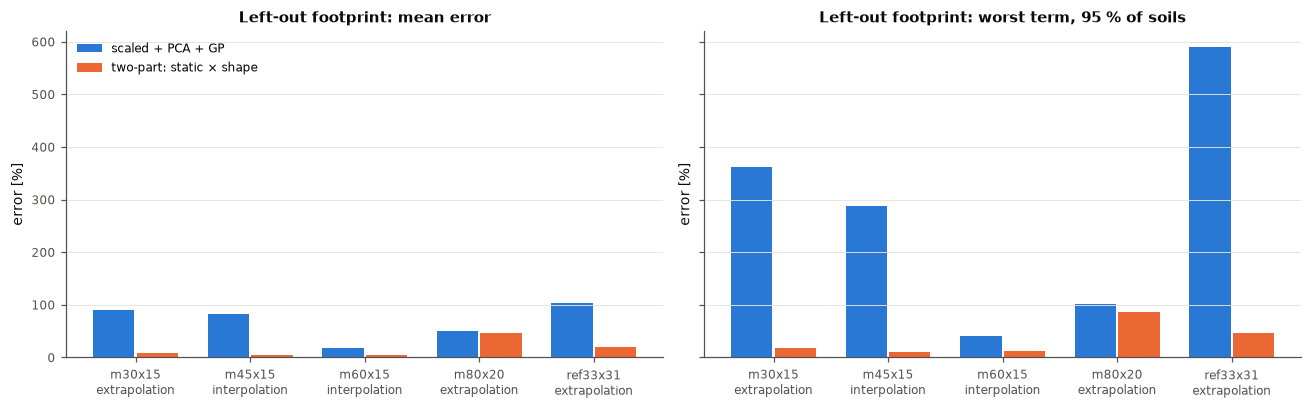

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
x = np.arange(len(MESHES))
for ax, metric, title in [(axes[0], "err_mean", "mean error"), (axes[1], "err_worst", "worst term, 95 % of soils")]:
    for k, name in enumerate(lofo):
        vals = [row(lofo[name][m]["errors"])[metric] for m in MESHES]
        ax.bar(x + (k - 0.5) * 0.38, vals, width=0.36, color=style.SERIES[k], label=name)
    ax.set_xticks(x, [f"{m}\n{KIND[m].split(' (')[0]}" for m in MESHES], fontsize=8)
    ax.set(title=f"Left-out footprint: {title}", ylabel="error [%]")
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper left")
fig.tight_layout()

## 4 · The static part on a new building

The two-part model predicts each term's static stiffness first. Here are its predictions for
the left-out footprints against MISS3D, for vertical, rocking and torsion (log scales: the
footprints span a factor of ~25 in rocking stiffness).

m30x15    static error, median over soils [%]: Ux 0.4  Uy 1.0  Uz 2.9  Rx 1.9  Ry 3.2  Rz 7.3  Ux-Ry 1.2  Uy-Rx 3.2
m45x15    static error, median over soils [%]: Ux 0.5  Uy 0.7  Uz 0.6  Rx 0.8  Ry 1.0  Rz 5.7  Ux-Ry 1.0  Uy-Rx 1.3
m60x15    static error, median over soils [%]: Ux 0.7  Uy 0.7  Uz 0.6  Rx 1.3  Ry 1.0  Rz 5.2  Ux-Ry 1.4  Uy-Rx 2.3
m80x20    static error, median over soils [%]: Ux 2.4  Uy 2.2  Uz 1.7  Rx 53.2  Ry 3.2  Rz 76.4  Ux-Ry 54.9  Uy-Rx 48.6
ref33x31  static error, median over soils [%]: Ux 5.8  Uy 5.4  Uz 4.1  Rx 7.7  Ry 8.2  Rz 33.0  Ux-Ry 14.9  Uy-Rx 5.9


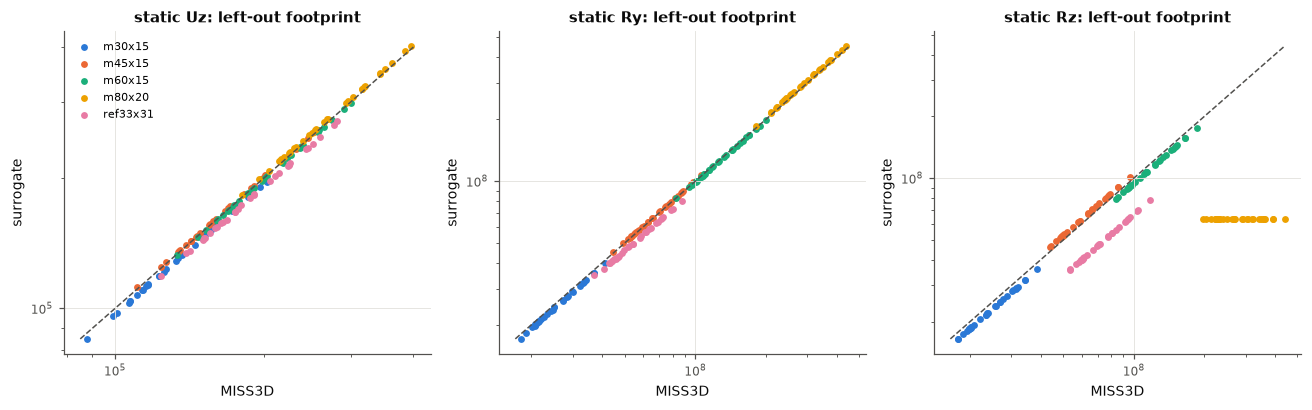

In [7]:
r_name = "two-part: static × shape"
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, term in zip(axes, ["Uz", "Ry", "Rz"]):
    t = terms.index(term)
    lo, hi = np.inf, 0
    for m in MESHES:
        r = lofo[r_name][m]
        true_s = targets_to_K(r["Y_true"], r["spec"])[:, 0, t].real
        pred_s = r["model"].predict_static(input_features(test_all.select(mesh=m), footprint=True)[0])[:, t]
        ax.scatter(true_s, pred_s, s=12, color=style.MESH_COLORS[m], label=m)
        lo, hi = min(lo, true_s.min(), pred_s.min()), max(hi, true_s.max(), pred_s.max())
    ax.plot([lo, hi], [lo, hi], color=style.INK2, lw=1, ls="--")
    ax.set(xscale="log", yscale="log", title=f"static {term}: left-out footprint",
           xlabel="MISS3D", ylabel="surrogate")
    ax.tick_params(which="minor", labelbottom=False, labelleft=False)
axes[0].legend(loc="upper left", fontsize=7)
fig.tight_layout()

for m in MESHES:
    r = lofo[r_name][m]
    true_s = targets_to_K(r["Y_true"], r["spec"])[:, 0, :].real
    pred_s = r["model"].predict_static(input_features(test_all.select(mesh=m), footprint=True)[0])
    err = 100 * np.abs(pred_s / true_s - 1)
    print(f"{m:9s} static error, median over soils [%]: " + "  ".join(f"{t} {v:.1f}" for t, v in zip(terms, np.median(err, axis=0))))

## 5 · An example: one new soil on a left-out footprint

The median test soil (by mean error) of each extrapolation case, two-part model, Re part.

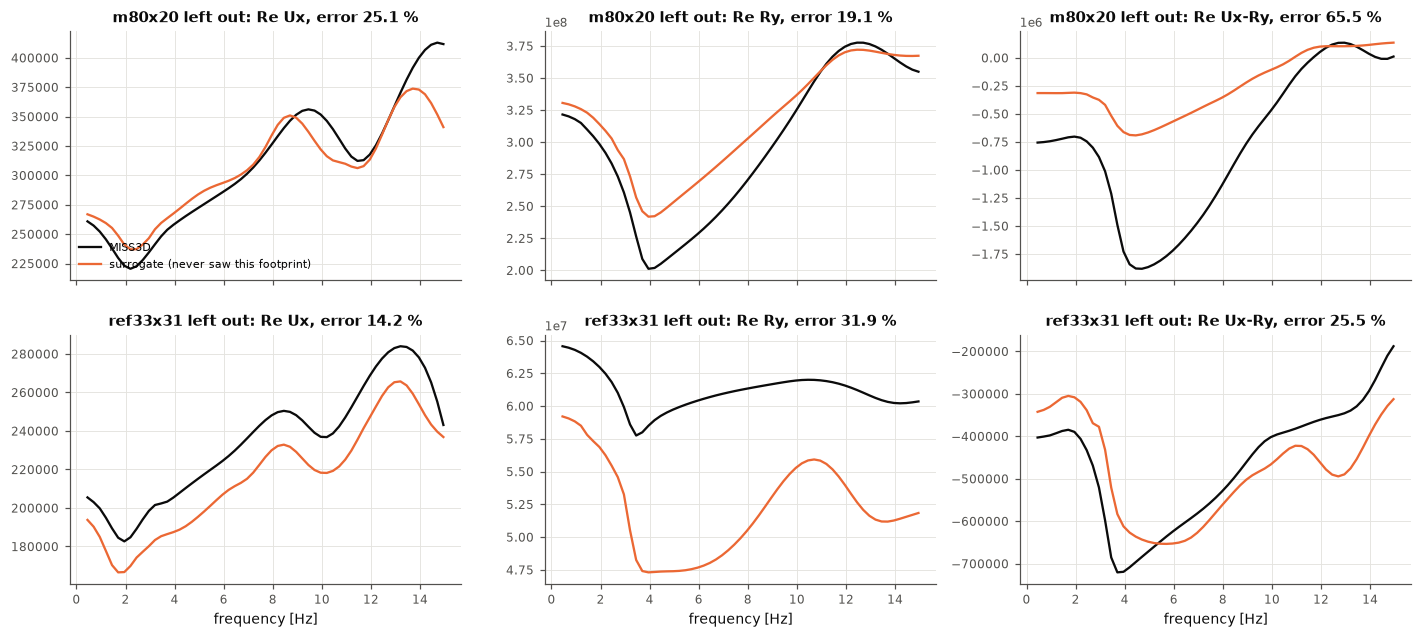

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for r_i, m in enumerate(["m80x20", "ref33x31"]):
    r = lofo[r_name][m]
    e = r["errors"]
    i = int(np.argsort(e.mean(axis=1))[len(e) // 2])
    Kt, Kp = targets_to_K(r["Y_true"], r["spec"]), targets_to_K(r["Y_pred"], r["spec"])
    for c, term in enumerate(["Ux", "Ry", "Ux-Ry"]):
        t = terms.index(term)
        ax = axes[r_i, c]
        ax.plot(f, Kt[i, :, t].real, color=style.INK, lw=1.5, label="MISS3D")
        ax.plot(f, Kp[i, :, t].real, color=style.SERIES[1], lw=1.5, label="surrogate (never saw this footprint)")
        ax.set_title(f"{m} left out: Re {term}, error {e[i, t]:.1f} %")
axes[0, 0].legend(loc="lower left", fontsize=7)
for ax in axes[1]:
    ax.set_xlabel("frequency [Hz]")
fig.tight_layout()

## 6 · Two fixes for the new-building case

Section 3 showed the weak spot: a footprint **outside** the training range. Two remedies, both
from physics rather than from more simulations:

1. **A linear trend under the GPs** ("universal kriging", kriging with a drift). A plain GP
   drifts back to the average away from its data, so for a raft longer than any it has seen it
   predicts a stiffness that is far too low. Static stiffness follows a power law in the
   footprint size, which is a straight line in log L, so a fitted linear trend can carry the
   prediction outside the data while the GP corrects it inside.
2. **Rotated twins** (data augmentation from a symmetry). On horizontally layered soil, a
   30 × 15 m raft turned by 90° is a 15 × 30 m raft, and its impedance follows exactly by
   swapping the axes (`rotate_90` in `surrogate/data.py`). Every training footprint gains a
   twin at no simulation cost, and the long-thin footprints now cover the "wide" side too, which
   is what the near-square ref33x31 needs. The left-out footprint's own twin is never used.

Tested on the three extrapolation footprints and one interpolation footprint, with N_FIX soils
per footprint (the twins double the cases, and the cost grows as n³).

In [9]:
FIX_MESHES = ["m30x15", "m80x20", "ref33x31", "m45x15"]
VARIANTS = {"two-part": dict(), "+ trend": dict(trend="all"),
            "+ trend + rotated twins": dict(trend="all", rotate=True)}
fixes = {}
for m in FIX_MESHES:
    train = train_all.take(train_all.mesh_id != m) if N_FIX == N_SOILS else \
        ds.select(split="train").take(ds.select(split="train").mesh_id != m).head_per_mesh(N_FIX)
    for name, kw in VARIANTS.items():
        r = fit_and_score(StaticShapeGP, train, test_all.select(mesh=m), **kw)
        fixes[(m, KIND[m], name)] = row(r["errors"])
        print(f"leave out {m:9s} {name:24s} cases {r['n_train']:5d}  fit {r['fit_s']:5.0f} s  "
              f"err_mean {r['errors'].mean():6.2f} %")
fix_table = pd.DataFrame(fixes).T[["err_mean", "err_worst"]].unstack(level=2)
fix_table.reindex(columns=pd.MultiIndex.from_product([["err_mean", "err_worst"], list(VARIANTS)])).round(2)

leave out m30x15    two-part                 cases   512  fit    32 s  err_mean   8.63 %


leave out m30x15    + trend                  cases   512  fit    30 s  err_mean   9.01 %


leave out m30x15    + trend + rotated twins  cases  1024  fit   181 s  err_mean   9.24 %


leave out m80x20    two-part                 cases   512  fit    32 s  err_mean  46.25 %


leave out m80x20    + trend                  cases   512  fit    32 s  err_mean  11.75 %


...

leave out ref33x31  + trend + rotated twins  cases  1024  fit   187 s  err_mean  12.59 %


leave out m45x15    two-part                 cases   512  fit    30 s  err_mean   5.42 %


leave out m45x15    + trend                  cases   512  fit    26 s  err_mean   5.16 %


leave out m45x15    + trend + rotated twins  cases  1024  fit   181 s  err_mean   5.34 %


err_mean          \
                                       two-part + trend   
m30x15   extrapolation (shortest)          8.63    9.01   
m45x15   interpolation                     5.42    5.16   
m80x20   extrapolation (longest)          46.25   11.75   
ref33x31 extrapolation (only L_y = 31)    20.07   21.69   

                                                               err_worst  \
                                       + trend + rotated twins  two-part   
m30x15   extrapolation (shortest)                         9.24     17.24   
m45x15   interpolation                                    5.34     12.42   
m80x20   extrapolation (longest)                         11.94     85.53   
ref33x31 extrapolation (only L_y = 31)                   12.59     45.28   

                                                                        
                                       + trend + trend + rotated twins  
m30x15   extrapolation (shortest)        21.97                   18.55  
m45x15   interpolation                   19.05                   13.11  
m80x20   extrapolation (longest)         37.57                   30.38  
ref33x31 extrapolation (only L_y = 31)   46.88                   25.91

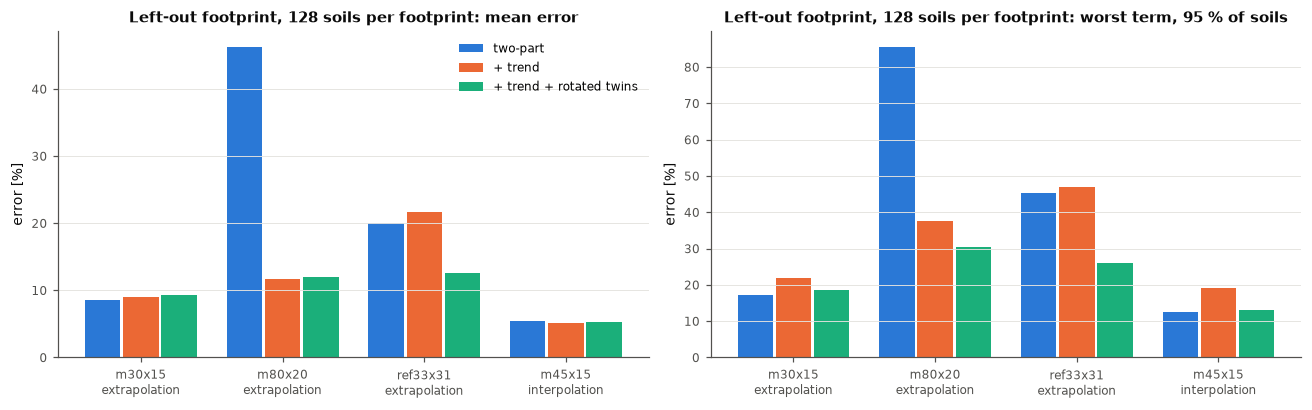

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
x = np.arange(len(FIX_MESHES))
for ax, metric, title in [(axes[0], "err_mean", "mean error"), (axes[1], "err_worst", "worst term, 95 % of soils")]:
    for k, name in enumerate(VARIANTS):
        vals = [fixes[(m, KIND[m], name)][metric] for m in FIX_MESHES]
        ax.bar(x + (k - 1) * 0.27, vals, width=0.25, color=style.SERIES[k], label=name)
    ax.set_xticks(x, [f"{m}\n{KIND[m].split(' (')[0]}" for m in FIX_MESHES], fontsize=8)
    ax.set(title=f"Left-out footprint, {N_FIX} soils per footprint: {title}", ylabel="error [%]")
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper right")
fig.tight_layout()

## 7 · The experiment table

In [11]:
band = f"{f[0]:g}-{f[-1]:g}"
LOG("M3-ref-band15", milestone="M3", footprints="ref33x31", validation="hold-out 32 random soils",
               band_hz=band, n_train=ref["n_train"], n_test=ref["n_test"], representation="per-term scaled, PCA 20",
               model="GP per coefficient, Matern 5/2 ARD", fit_s=ref["fit_s"], predict_ms_per_case=ref["pred_ms"],
               notes="Milestone 2 model in the 0.45-15 Hz band", **summarize(ref["errors"], terms))
rep_names = {"scaled + PCA + GP": ("pcagp", "per-term scaled, PCA 20", "GP per coefficient, Matern 5/2 ARD"),
             "two-part: static × shape": ("static", "static (log) + shape, PCA 20", "GP per log-static and per shape coefficient")}
for name, (tag, rep, model_txt) in rep_names.items():
    r = runs[name]
    LOG(f"M3-all-{tag}", milestone="M3", footprints="all 5", validation="hold-out 32 soils per footprint",
                   band_hz=band, n_train=r["n_train"], n_test=r["n_test"], representation=rep, model=model_txt,
                   fit_s=r["fit_s"], predict_ms_per_case=r["pred_ms"], notes=f"{N_SOILS} soils per footprint",
                   **summarize(r["errors"], terms))
    pooled = np.vstack([lofo[name][m]["errors"] for m in MESHES])
    inter = np.vstack([lofo[name][m]["errors"] for m in MESHES if KIND[m] == "interpolation"])
    for subset, errs in [("all", pooled), ("interp", inter)]:
        LOG(f"M3-lofo-{tag}-{subset}", milestone="M3",
                       footprints="5 left out in turn" if subset == "all" else "m45x15, m60x15 left out in turn",
                       validation="leave one footprint out, its 32 hold-out soils", band_hz=band,
                       n_train=lofo[name][MESHES[0]]["n_train"], n_test=len(errs), representation=rep, model=model_txt,
                       fit_s=float(np.mean([lofo[name][m]["fit_s"] for m in MESHES])),
                       notes=f"{N_SOILS} soils per training footprint; errors pooled over the left-out footprints",
                       **summarize(errs, terms))
for name, tag in [("+ trend", "trend"), ("+ trend + rotated twins", "trend-rot")]:
    for kind_sel, subset in [(None, "4"), ("interpolation", "interp")]:
        errs_rows = [m for m in FIX_MESHES if kind_sel is None or KIND[m] == kind_sel]
        mean_of = lambda key: float(np.mean([fixes[(m, KIND[m], name)][key] for m in errs_rows]))
        LOG(f"M3-fix-{tag}-{subset}", milestone="M3",
                       footprints=", ".join(errs_rows) + " left out in turn",
                       validation="leave one footprint out, its 32 hold-out soils", band_hz=band,
                       n_test=32 * len(errs_rows), representation="static (log) + shape, PCA 20",
                       model=f"GP per target, Matern 5/2 ARD, linear trend{', rotated twins' if 'rot' in tag else ''}",
                       notes=f"{N_FIX} soils per training footprint; err_* are means over the left-out footprints",
                       **{f"err_{t}": mean_of(t) for t in terms}, err_worst=mean_of("err_worst"), err_mean=mean_of("err_mean"))
read_experiments()[["exp_id", "footprints", "band_hz", "n_train", "err_worst", "err_mean"]]

,exp_id,footprints,band_hz,n_train,err_worst,err_mean
0,M3b-gpu-check256,all 5,0.45-14.95,1280.0,11.030,3.192
1,M3b-gpu-all,all 5,0.45-14.95,5120.0,8.615,2.911
2,M3b-gpu-lofo-all,5 left out in turn,0.45-14.95,2048.0,77.760,8.682
3,M3b-gpu-lofo-interp,"m45x15, m60x15 left out in turn",0.45-14.95,2048.0,11.880,4.661
4,M5-release,all 5,0.45-14.95,5120.0,8.611,2.909
5,M2-mean,ref33x31,0.45-33.2,1024.0,78.370,33.590
6,M2-knn,ref33x31,0.45-33.2,1024.0,55.790,18.010
7,M2-pcagp40,ref33x31,0.45-33.2,1024.0,47.390,11.450
8,M2-pcagp40-low,ref33x31,0.45-10,1024.0,7.791,1.383
9,M3-ref-band15,ref33x31,0.45-14.95,1024.0,5.380,1.505


## 8 · Findings

Numbers from the reference run (deterministic; your errors will match, timings will not).
Band 0.45–15 Hz; errors in % as defined in notebook 02 (err_mean: typical; err_worst: the worst
term's 95th percentile over the test soils).

**1 · The band decision alone** (ref33x31, 1,024 soils, Milestone 2 model): err_mean **1.50 %**,
err_worst **5.38 %** (Ux, Uy; couplings 4.9 %, rocking ≤ 1.1 %), against 11.5 % and 47.4 % over
0.45–33.2 Hz in notebook 02.

**2 · All five footprints, new soils** (256 soils × 5 = 1,280 cases):

| Representation | err_mean | err_worst |
|---|---|---|
| scaled + PCA + GP | 4.23 % | 12.3 % |
| two-part: static × shape | **3.21 %** | **10.9 %** |

Per footprint (two-part): m30x15 2.5 / 7.5 %, m45x15 2.8 / 9.2 %, m60x15 3.2 / 11.3 %, m80x20
4.3 / 16.2 %, ref33x31 3.3 / 10.9 %. With a quarter of the soils per footprint and two more
inputs, the error is about twice the single-footprint figure.

**3 · Leave one footprint out** (256 soils × 4 = 1,024 cases; two-part model):

| Left out | Kind | err_mean | err_worst |
|---|---|---|---|
| m45x15 | interpolation | 4.9 % | 11.3 % |
| m60x15 | interpolation | 5.6 % | 11.5 % |
| m30x15 | extrapolation (shortest) | 8.7 % | 17.3 % |
| ref33x31 | extrapolation (only L_y = 31) | 19.8 % | 46.6 % |
| m80x20 | extrapolation (longest) | 45.8 % | 85.5 % |

The scaled model fails whenever the footprint is new (with m30x15 left out: 90 % mean error,
362 % worst term): scaling all footprints by one constant per term leaves it to the GP to learn
a 25-fold range of rocking stiffness, which it cannot extrapolate. Working with log static
stiffness is what makes the two-part model usable at all. Its failures in the extrapolation
cases come mostly from the static part (section 4): for m80x20 the predicted static Rx and Rz
are off by 50–75 % because the GP flattens out beyond L_x = 60 m.

**6 · The two fixes** (128 soils per footprint; err_mean / err_worst):

| Left out | two-part | + trend | + trend + rotated twins |
|---|---|---|---|
| m30x15 | 8.6 / 17.2 | 9.0 / 22.0 | 9.2 / 18.6 |
| m80x20 | 46.3 / 85.5 | 11.8 / 37.6 | 12.0 / 30.4 |
| ref33x31 | 20.1 / 45.3 | 21.7 / 46.9 | **12.6 / 25.9** |
| m45x15 | 5.4 / 12.4 | 5.2 / 19.1 | 5.3 / 13.1 |
| **average** | 20.1 / 40.1 | 11.9 / 31.4 | **9.8 / 22.0** |

- The **trend** rescues the longest raft (m80x20: 46 % → 12 %), whose static stiffness lies on
  the power law beyond the training range.
- The **rotated twins** rescue the near-square raft (ref33x31: 20 % → 13 %): turning the long
  rafts by 90° puts "wide" footprints into training, so L_y = 31 m is no longer far outside it.
- Together they halve the average error over the four left-out footprints and almost halve the
  worst term, at no simulation cost. They change little where the model was already
  interpolating.

**What remains.** A new footprint inside the training range: ~5 % typical. Outside it, ~10–13 %
typical with the fixes, still 20–30 % on the worst term. The limit is the variety of footprints
(five, all but one long and thin), not the model. New meshes, squarer and wider (e.g. 40 × 40,
60 × 40), would convert the hard extrapolation cases into interpolation.

**Next: notebook 04** trains the fixed recipe on the GPU with all the soils.